In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above_ring", "stalk_surface_below_ring",
    "stalk_color_above_ring", "stalk_color_below_ring",
    "veil_type", "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/mushroom/"
    "agaricus-lepiota.data"
)

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


SyntaxError: unmatched ']' (2764304804.py, line 8)

In [5]:
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above_ring", "stalk_surface_below_ring",
    "stalk_color_above_ring", "stalk_color_below_ring",
    "veil_type", "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/mushroom/"
    "agaricus-lepiota.data"
)

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


SyntaxError: unmatched ']' (2764304804.py, line 8)

In [6]:

columns = [
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above_ring", "stalk_surface_below_ring",
    "stalk_color_above_ring", "stalk_color_below_ring",
    "veil_type", "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/mushroom/"
    "agaricus-lepiota.data"
)

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (8124, 23)


,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [7]:

# In this dataset, ? represents a missing value
df = df.replace("?", np.nan)

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Input features
X = df.drop(columns=["class"])

# Target: e = edible, p = poisonous
y = df["class"]

print("\nFeature shape:", X.shape)
print("Target distribution:")
print(y.value_counts())


Missing values in each column:
class                          0
cap_shape                      0
cap_surface                    0
cap_color                      0
bruises                        0
odor                           0
gill_attachment                0
gill_spacing                   0
gill_size                      0
gill_color                     0
stalk_shape                    0
stalk_root                  2480
stalk_surface_above_ring       0
stalk_surface_below_ring       0
stalk_color_above_ring         0
stalk_color_below_ring         0
veil_type                      0
veil_color                     0
ring_number                    0
ring_type                      0
spore_print_color              0
population                     0
habitat                        0
dtype: int64

Duplicate rows: 0

Feature shape: (8124, 22)
Target distribution:
class
e    4208
p    3916
Name: count, dtype: int64


In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 6499
Testing samples: 1625


In [9]:

decision_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("model", DecisionTreeClassifier(random_state=42))
])

decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")


Decision Tree Accuracy: 100.0 %


In [10]:

knn = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)

knn_predictions = knn.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")


KNN Accuracy: 100.0 %


In [11]:

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy (%)": [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(results.round(2))

best_model = (
    "Decision Tree"
    if dt_accuracy > knn_accuracy
    else "KNN"
    if knn_accuracy > dt_accuracy
    else "Both models tied"
)

print("Better model based on accuracy:", best_model)


,Model,Accuracy (%)
0,Decision Tree,100.0
1,KNN,100.0


Better model based on accuracy: Both models tied


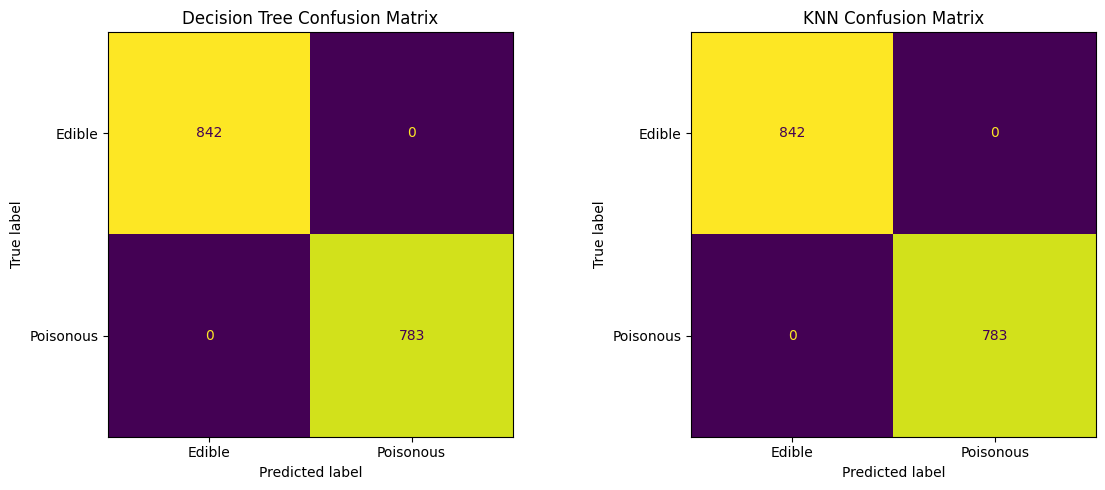

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("KNN Confusion Matrix")

plt.tight_layout()
plt.show()


## Conclusion

In this project, I developed a machine learning model to classify mushrooms as edible or poisonous using the UCI Mushroom dataset.

I implemented two classification algorithms: Decision Tree and K-Nearest Neighbors (KNN). I checked for missing values, prepared the categorical features, split the data into training and testing sets, and evaluated both models using accuracy and confusion matrices.

The Decision Tree achieved an accuracy of **[100]%**, while KNN achieved an accuracy of **[100]%**.

Based on the test accuracy, **[both models tied]** performed better on this dataset. The confusion matrices helped me understand the correct and incorrect predictions made by each model.

Through this project, I learned how to prepare a dataset, train classification models, evaluate their performance, and compare machine learning algorithms.

## Conclusion

In this project, I developed a machine learning model to classify mushrooms as edible or poisonous using the Mushroom dataset.

I implemented two algorithms: Decision Tree and K-Nearest Neighbors (KNN). I checked missing values, prepared the features, split the dataset into training and testing sets, and evaluated the models using accuracy and confusion matrices.

The Decision Tree achieved an accuracy of [100]%, while KNN achieved an accuracy of [100]%.

Based on the accuracy results, [your better-performing model] performed better in this experiment.

Through this project, I learned how to load and prepare data, train machine learning models, evaluate their performance, and compare classification algorithms.

This model is for educational purposes only and should not be used to determine whether real mushrooms are safe to eat.

## Conclusion

In this project, I developed a machine learning model to classify mushrooms as edible or poisonous using the Mushroom dataset.

I implemented two algorithms: Decision Tree and K-Nearest Neighbors (KNN). I checked missing values, prepared the features, split the dataset into training and testing sets, and evaluated the models using accuracy and confusion matrices.

The Decision Tree achieved an accuracy of [100]%, while KNN achieved an accuracy of [100]%.

Based on the accuracy results, [## Conclusion

In this project, I developed a machine learning model to classify mushrooms as edible or poisonous using the Mushroom dataset.

I implemented two algorithms: Decision Tree and K-Nearest Neighbors (KNN). I checked missing values, prepared the features, split the dataset into training and testing sets, and evaluated the models using accuracy and confusion matrices.

The Decision Tree achieved an accuracy of [100]%, while KNN achieved an accuracy of [100]%.

Based on the accuracy results, [best_model] performed better in this experiment.

Through this project, I learned how to load and prepare data, train machine learning models, evaluate their performance, and compare classification algorithms.

This model is for educational purposes only and should not be used to determine whether real mushrooms are safe to eat.] performed better in this experiment.

Through this project, I learned how to load and prepare data, train machine learning models, evaluate their performance, and compare classification algorithms.

This model is for educational purposes only and should not be used to determine whether real mushrooms are safe to eat.